## Praktiskais darbs: 3D sejas rekonstrukcija no viena 2D attēla
**Metode:** DECA

**Pārbaudītā vide:** Google Colab izpildlaiks 2025.10, Tesla T4, atsevišķa Python 3.10.12 vide, PyTorch 2.5.1+cu124, torchvision 0.20.1+cu124. Sistēmas CUDA kompilators: 12.5.82, g++: 11.4.0. Colab pamata Python bija 3.12.12; DECA izmanto /content/deca-env/bin/python.


## 1. Uzņemt un sagatavot divus fotoattēlus

Praktiskajā darbā tika izmantoti divi pašu uzņemti fotoattēli - frontal.jpg, kurā seja redzama pretskatā, un profile.jpg, kurā galva pagriezta aptuveni 90° profilā. Sākotnējie attēli tika saglabāti atsevišķi no priekšapstrādātajām kopijām un netika pārveidoti. Abi attēli uzņemti vienā sesijā, ar līdzīgu attālumu un apgaismojumu, bez filtriem, ar neitrālu izteiksmi un aizvērtu muti

Darba kopijām tika piemērota EXIF metadatos norādītā orientācija un RGB krāsu formāts, kā arī attēli tika proporcionāli samazināti līdz 1600 pikseļiem garākajā malā un saglabāti JPEG formātā ar kvalitātes parametru 95. Abu darba kopiju izmērs pēc priekšapstrādes bija 1200 x 1600 pikseļi. Rekonstrukcijas laikā DECA papildus automātiski noteica seju un sagatavoja apgrieztu 224 x 224 pikseļu ievadi.

## 2. Izvēlēties un konfigurēt rekonstrukcijas metodi

Praktiskajā darbā tika izmantota metode DECA, kas no viena attēla iegūst sejas formu, izteiksmi un smalkas virsmas detaļas. Tika izvēlēta šī metode, jo tā ļauj saglabāt rekonstruēto ģeometriju OBJ formātā un apskatīt rezultātu no dažādiem skatpunktiem. Tika izmantota oficiālā DECA realizācija (https://github.com/yfeng95/DECA) un iepriekš apmācītie modeļa svari, neveicot modeļa apmācību no sākuma.

Darbs tika veikts Google Colab vidē ar Tesla T4 grafisko procesoru, un, tā kā DECA sākotnējās atkarības paredz vecākas programmatūras versijas, tika izveidota atsevišķa Python 3.10 vide un instalēts PyTorch 2.5.1 ar CUDA 12.4 atbalstu. Atkarību konfliktu novēršanai Kornia 0.4.0 tika aizstāta ar 0.6.12, savukārt NumPy tika izmantota 1.23.5 versija savietojamībai ar vecākajām bibliotēkām.

Sākotnējā projekta kodā tika veikti trīs saderības labojumi. Failā `decalib/utils/renderer.py` C++14 iestatījums tika aizstāts ar C++17 un noņemta piesaiste kompilatoram `gcc-7`. Failā `decalib/utils/rasterizer/standard_rasterize_cuda_kernel.cu` novecojušie datu tipa un atmiņas piekļuves izsaukumi tika aizstāti ar `scalar_type()` un `data_ptr<...>()`. Failā `decalib/datasets/detectors.py` nosaukums `LandmarksType._2D` tika aizstāts ar instalētajā bibliotēkā pieejamo `LandmarksType.TWO_D`. Šie labojumi pielāgoja projekta saskarnes izmantotajai videi, nemainot rekonstrukcijas metodi.

FLAME2020 modelis tika iegūts no oficiālās FLAME vietnes (https://flame.is.tue.mpg.de/download.php), ievērojot tā piekļuves un licences nosacījumus. Fails `generic_model.pkl` tika ievietots DECA mapē `data`, un iepriekš apmācītie DECA svari tika lejupielādēti, izmantojot projekta `fetch_data.sh` norādīto Google Drive faila identifikatoru, un saglabāti kā `data/deca_model.tar`. Papildu albedo modelis netika izmantots.

In [1]:
import sys
import torch

# Izvada pašreizējās Colab vides Python, PyTorch un CUDA versijas
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)

# Pārbauda, vai PyTorch var izmantot CUDA grafisko procesoru
print("GPU pieejams:", torch.cuda.is_available())

# Izvada pirmā grafiskā procesora nosaukumu, ja tas ir pieejams
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Parāda NVIDIA draivera, GPU atmiņas un noslodzes informāciju
!nvidia-smi

Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
PyTorch: 2.8.0+cu126
PyTorch CUDA: 12.6
GPU pieejams: True
GPU: Tesla T4
Wed Nov 11 14:54:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|       

In [2]:
# Pārslēdz darba direktoriju uz Colab sesijas pamatmapi
%cd /content

# Nokopē oficiālo DECA repozitoriju mapē /content/DECA
!git clone https://github.com/yfeng95/DECA.git

# Izvada lejupielādētās koda versijas komita identifikatoru
!git -C /content/DECA rev-parse HEAD

/content
Cloning into 'DECA'...
remote: Enumerating objects: 445, done.
remote: Counting objects: 100% (227/227), done.
remote: Compressing objects: 100% (78/78), done.
remote: Total 445 (delta 164), reused 149 (delta 149), pack-reused 218 (from 1)
Receiving objects: 100% (445/445), 22.95 MiB | 14.54 MiB/s, done.
Resolving deltas: 100% (199/199), done.
a11554ae2a2b0f3998cf1fa94dd4db03babb34a2


In [3]:
import subprocess
import sys

# Instalē uv rīku, izmantojot pašreizējās Colab vides Python
# Parametrs check=True kļūdas gadījumā aptur šūnas izpildi
subprocess.run(
    [sys.executable, "-m", "pip", "install", "uv"],
    check=True
)

# Izveido atsevišķu Python 3.10 vidi mapē /content/deca-env
# Ja nepieciešams, lejupielādē Python; ar --seed pievieno pip un saistītos rīkus
subprocess.run(
    [sys.executable, "-m", "uv", "venv",
     "--python", "3.10", "--seed", "/content/deca-env"],
    check=True
)

# Izvada jaunizveidotās DECA vides Python versiju
subprocess.run(
    ["/content/deca-env/bin/python", "--version"],
    check=True
)

CompletedProcess(args=['/content/deca-env/bin/python', '--version'], returncode=0)

In [4]:
import subprocess

# Instalē izvēlēto PyTorch un torchvision pāri DECA vidē
subprocess.run(
    [
        "/content/deca-env/bin/python", "-m", "pip", "install",
        "torch==2.5.1", "torchvision==0.20.1",
        "--index-url", "https://download.pytorch.org/whl/cu124"
    ],
    check=True
)

# Pārbauda versijas un izpilda nelielu aprēķinu uz GPU
parbaude = """
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("PyTorch CUDA:", torch.version.cuda)
assert torch.cuda.is_available(), "GPU nav pieejams"
print("GPU:", torch.cuda.get_device_name(0))

x = torch.tensor([1.0, 2.0, 3.0], device="cuda")
print("GPU aprēķina rezultāts:", (x * 2).cpu().tolist())
"""

subprocess.run(
    ["/content/deca-env/bin/python", "-c", parbaude],
    check=True
)

CompletedProcess(args=['/content/deca-env/bin/python', '-c', '\nimport torch\nimport torchvision\n\nprint("PyTorch:", torch.__version__)\nprint("torchvision:", torchvision.__version__)\nprint("PyTorch CUDA:", torch.version.cuda)\nassert torch.cuda.is_available(), "GPU nav pieejams"\nprint("GPU:", torch.cuda.get_device_name(0))\n\nx = torch.tensor([1.0, 2.0, 3.0], device="cuda")\nprint("GPU aprēķina rezultāts:", (x * 2).cpu().tolist())\n'], returncode=0)

In [5]:
import subprocess

# Norāda DECA atsevišķās vides Python
deca_python = "/content/deca-env/bin/python"

# Nosaka instalējamās versijas un saglabā izvēlēto PyTorch pāri
pakotnes = [
    "torch==2.5.1", "torchvision==0.20.1",
    "numpy==1.23.5", "scipy==1.10.1",
    "scikit-image==0.21.0", "opencv-python==4.8.1.78",
    "matplotlib==3.7.5", "Pillow==10.4.0",
    "PyYAML==6.0.2", "yacs==0.1.8",
    "kornia==0.6.12", "face-alignment==1.3.5",
    "numba==0.60.0", "ninja==1.11.1.3",
    "fvcore==0.1.5.post20221221"
]

# Instalē pamatatkarības DECA vidē
subprocess.run(
    [deca_python, "-m", "pip", "install", *pakotnes],
    check=True
)

# Pārbauda instalēto pakotņu deklarēto atkarību saderību
rezultats = subprocess.run(
    [deca_python, "-m", "pip", "check"],
    check=True, capture_output=True, text=True
)
print(rezultats.stdout)

No broken requirements found.



In [6]:
import subprocess

# Norāda DECA vides Python
deca_python = "/content/deca-env/bin/python"

# Izpilda komandu, parāda izvadi un kļūdas gadījumā aptur šūnu
def izpilda(argumenti):
    rezultats = subprocess.run(
        [deca_python, *argumenti],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )
    print(rezultats.stdout)
    rezultats.check_returncode()

# Sagatavo vecākās bibliotēkas būvēšanai nepieciešamos rīkus
izpilda([
    "-m", "pip", "install",
    "setuptools==69.5.1", "wheel==0.45.1"
])

# Instalē chumpy, izmantojot sagatavoto vidi
izpilda([
    "-m", "pip", "install",
    "--no-build-isolation", "chumpy==0.70"
])

# Pārbauda bibliotēkas importēšanu
izpilda([
    "-c",
    "import chumpy; print('chumpy imports: OK')"
])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 894.6/894.6 kB 12.3 MB/s  0:00:00
  Attempting uninstall: wheel
    Found existing installation: wheel 0.48.0
    Uninstalling wheel-0.48.0:
      Successfully uninstalled wheel-0.48.0
  Attempting uninstall: setuptools
    Found existing installation: setuptools 84.2.1
    Uninstalling setuptools-84.2.1:
      Successfully uninstalled setuptools-84.2.1


  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for chumpy: filename=chumpy-0.70-py3-none-any.whl size=58264 sha256=e71ddbdb8f2c612ce2cf1be41cfc2a4828ce4d9d100944310f97d702ccf7ca69
  Stored in directory: /root/.cache/pip/wheels/e0/c1/ef/29ba7be03653a29ef6f2c3e1956d6c4d8877f2b243af411db1
Successfully built chumpy

chumpy imports: OK



In [7]:
from pathlib import Path
import subprocess

# Norāda precīzos saderības labojumus abiem failiem
labojumi = {
    "decalib/utils/renderer.py": [
        ("'-std=c++14', '-ccbin=$$(which gcc-7)'", "'-std=c++17'")
    ],
    "decalib/utils/rasterizer/standard_rasterize_cuda_kernel.cu": [
        ("face_vertices.type()", "face_vertices.scalar_type()"),
        (".data<", ".data_ptr<")
    ]
}

for nosaukums, aizvietojumi in labojumi.items():
    fails = Path("/content/DECA") / nosaukums
    teksts = fails.read_text()

    # Saglabā sākotnējā faila rezerves kopiju
    rezerve = fails.with_name(fails.name + ".original")
    if not rezerve.exists():
        rezerve.write_bytes(fails.read_bytes())

    # Pārbauda un piemēro norādītos aizvietojumus
    for vecais, jaunais in aizvietojumi:
        assert vecais in teksts, f"Nav atrasta paredzētā vieta: {vecais}"
        teksts = teksts.replace(vecais, jaunais)

    fails.write_text(teksts)
    print("Labots:", nosaukums)

# Parāda izmaiņas salīdzinājumā ar sākotnējo Git kodu
izvade = subprocess.run(
    ["git", "-C", "/content/DECA", "diff", "--stat"],
    capture_output=True, text=True, check=True
)
print(izvade.stdout)

Labots: decalib/utils/renderer.py
Labots: decalib/utils/rasterizer/standard_rasterize_cuda_kernel.cu
 .../rasterizer/standard_rasterize_cuda_kernel.cu   | 44 +++++++++++-----------
 decalib/utils/renderer.py                          |  2 +-
 2 files changed, 23 insertions(+), 23 deletions(-)



In [8]:
from pathlib import Path
import subprocess

# Pārbauda instalēto versiju un vajadzīgā nosaukuma pieejamību
parbaude = subprocess.run(
    [
        "/content/deca-env/bin/python", "-c",
        """
from importlib.metadata import version
import face_alignment

print("face-alignment:", version("face-alignment"))
print("Pieejamie tipi:", list(face_alignment.LandmarksType.__members__))
assert hasattr(face_alignment.LandmarksType, "TWO_D"), "TWO_D nav pieejams"
"""
    ],
    capture_output=True, text=True
)
print(parbaude.stdout)
print(parbaude.stderr)
parbaude.check_returncode()

# Nolasa DECA sejas noteicēja kodu
fails = Path("/content/DECA/decalib/datasets/detectors.py")
teksts = fails.read_text()
vecais = "face_alignment.LandmarksType._2D"
jaunais = "face_alignment.LandmarksType.TWO_D"
assert teksts.count(vecais) == 1, "Nav atrasta viena paredzētā labojuma vieta."

# Saglabā rezerves kopiju un aizstāj tikai tipa nosaukumu
rezerve = fails.with_name(fails.name + ".original")
if not rezerve.exists():
    rezerve.write_bytes(fails.read_bytes())

fails.write_text(teksts.replace(vecais, jaunais))
print("Labots: LandmarksType._2D → LandmarksType.TWO_D")

face-alignment: 1.3.5
Pieejamie tipi: ['TWO_D', 'TWO_HALF_D', 'THREE_D']


Labots: LandmarksType._2D → LandmarksType.TWO_D


In [9]:
from google.colab import files

# Atver faila izvēli FLAME2020 arhīva augšupielādei
augšuplādētie_faili = files.upload()

# Parāda saņemtā faila nosaukumu un izmēru
for nosaukums, saturs in augšuplādētie_faili.items():
    print(f"Saņemts: {nosaukums} ({len(saturs) / 1024**2:.1f} MB)")

Saving FLAME2020.zip to FLAME2020.zip
Saņemts: FLAME2020.zip (146.7 MB)


In [10]:
from pathlib import Path
import shutil
import zipfile

# Atrod iepriekšējā solī augšupielādēto arhīvu
arhivs = Path("FLAME2020.zip").resolve()
merkis = Path("/content/DECA/data/generic_model.pkl")

with zipfile.ZipFile(arhivs) as zip_fails:
    # Atrod modeļa failu neatkarīgi no arhīva mapju struktūras
    kandidati = [
        nosaukums for nosaukums in zip_fails.namelist()
        if Path(nosaukums).name == "generic_model.pkl"
        and "__MACOSX" not in Path(nosaukums).parts
    ]
    assert len(kandidati) == 1, (
        f"Arhīvā jābūt vienam generic_model.pkl; atrasti: {kandidati}"
    )

    # Pārbauda, vai mērķa fails jau neeksistē
    assert not merkis.exists(), f"Fails jau eksistē: {merkis}"
    merkis.parent.mkdir(parents=True, exist_ok=True)

    # Nokopē modeļa failu uz DECA paredzēto vietu
    with zip_fails.open(kandidati[0]) as avots:
        with merkis.open("xb") as izvade:
            shutil.copyfileobj(avots, izvade)

# Pārbauda saglabātā faila izmēru
assert merkis.stat().st_size > 0, "Modeļa fails ir tukšs"
print("Saglabāts:", merkis)
print(f"Izmērs: {merkis.stat().st_size / 1024**2:.1f} MB")

Saglabāts: /content/DECA/data/generic_model.pkl
Izmērs: 50.6 MB


In [11]:
import subprocess
from pathlib import Path

# Norāda DECA vides Python un svaru saglabāšanas vietu
deca_python = "/content/deca-env/bin/python"
svaru_fails = Path("/content/DECA/data/deca_model.tar")
assert not svaru_fails.exists(), "Svaru fails jau eksistē; vispirms tas jāpārbauda."

# Instalē Google Drive lejupielādes rīku
instalesana = subprocess.run(
    [deca_python, "-m", "pip", "install", "gdown==5.2.0"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
)
print(instalesana.stdout)
instalesana.check_returncode()

# Lejupielādē oficiālajā DECA skriptā norādīto failu
lejupielade = subprocess.run(
    [
        deca_python, "-m", "gdown",
        "1rp8kdyLPvErw2dTmqtjISRVvQLj6Yzje",
        "-O", str(svaru_fails)
    ],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
)
print(lejupielade.stdout)
lejupielade.check_returncode()

# Pārbauda, vai lejupielādētais fails nav tukšs
assert svaru_fails.stat().st_size > 0, "Lejupielādētais fails ir tukšs."
print("Saglabāts:", svaru_fails)
print(f"Izmērs: {svaru_fails.stat().st_size / 1024**2:.1f} MB")



Downloading...
From (original): https://drive.google.com/uc?id=1rp8kdyLPvErw2dTmqtjISRVvQLj6Yzje
From (redirected): https://drive.google.com/uc?id=1rp8kdyLPvErw2dTmqtjISRVvQLj6Yzje&confirm=t&uuid=03666694-ac0f-4c07-a8e8-5c8a5fb62976
To: /content/DECA/data/deca_model.tar

  0%|          | 0.00/434M [00:00<?, ?B/s]
  0%|          | 2.10M/434M [00:00<00:21, 20.0MB/s]
  1%|          | 4.72M/434M [00:00<00:19, 22.0MB/s]
  2%|▏         | 7.34M/434M [00:00<00:21, 19.7MB/s]
  4%|▍         | 17.3M/434M [00:00<00:12, 33.2MB/s]
  6%|▋         | 27.8M/434M [00:00<00:12, 31.8MB/s]
  9%|▉         | 38.3M/434M [00:01<00:12, 32.9MB/s]
 12%|█▏        | 50.9M/434M [00:01<00:09, 40.4MB/s]
 14%|█▍        | 61.3M/434M [00:01<00:08, 44.8MB/s]
 15%|█▌        | 66.1M/434M [00:01<00:08, 42.7MB/s]
 18%|█▊        | 78.1M/434M [00:01<00:07, 47.7MB/s]
 20%|█▉        | 86.5M/434M [00:02<00:06, 53.2MB/s]
 21%|██▏       | 92.8M/434M [00:02<00:06, 53.7MB/s]
 23%|██▎       | 101M/434M [00:02<00:05, 60.2MB/s] 
 25%|██

## 3. Palaist rekonstrukciju ar saviem fotoattēliem

Rekonstrukcijai tika izmantoti divi pašu uzņemti attēli - `frontal.jpg` un `profile.jpg`. Oriģināli tika saglabāti mapēs `inputs/originals/frontal` un `inputs/originals/profile`, savukārt priekšapstrādātās kopijas - atbilstošajās `inputs/processed` mapēs. Oriģināli netika pārrakstīti, un abām darba kopijām tika piemērota iepriekš aprakstītā priekšapstrāde, iegūstot 1200 x 1600 pikseļu attēlus.

Vispirms tika apstrādāts pretskata attēls, bet pēc tā rezultāta pārbaudes atsevišķi tika palaista profila rekonstrukcija. Abos gadījumos tika izmantots oficiālais skripts `demos/demo_reconstruct.py` ar vienādiem iestatījumiem. Parametrs `--iscrop True` nodrošināja sejas automātisku noteikšanu un apgriešanu, `--rasterizer_type standard` izvēlējās sagatavoto renderētāju, bet `--useTex False` ļāva neizmantot papildu albedo modeli. Ar `--saveObj True`, `--saveVis True` un `--saveImages True` tika saglabāti 3D režģi un rezultātu vizualizācijas. Parametrs `--render_orig False` atslēdza papildu renderēšanu sākotnējās ievades izšķirtspējā.

Pretskata rezultāti tika saglabāti mapē `results/frontal`, bet profila rezultāti - `results/profile`. Katrai ievadei tika iegūts pamata un detalizēts OBJ modelis, vizualizāciju attēli un izpildes žurnāls `reconstruction.log`. Abas izpildes beidzās ar atgriešanās kodu 0, un žurnālos netika konstatēts paziņojums par nenoteiktu seju. Rezultāti papildus tika apskatīti vizuāli, kā arī abi attēli tika apstrādāti neatkarīgi un netika apvienoti vienā modelī.

In [12]:
from pathlib import Path
from google.colab import files

# Izveido atsevišķu mapi pretskata oriģinālam
ievades_mape = Path("/content/DECA/inputs/originals/frontal")
ievades_mape.mkdir(parents=True, exist_ok=True)
merkis = ievades_mape / "frontal.jpg"
assert not merkis.exists(), "Pretskata fails jau eksistē."

# Atver viena oriģinālā JPG fotoattēla izvēli
augšuplade = files.upload()
assert len(augšuplade) == 1, "Jāizvēlas tikai pretskata fotoattēls."

# Saglabā oriģināla kopiju, nemainot attēla saturu
saturs = next(iter(augšuplade.values()))
assert saturs.startswith(b"\xff\xd8\xff"), "Izvēlētajam failam jābūt JPEG formātā."
with merkis.open("xb") as fails:
    fails.write(saturs)

print("Saglabāts:", merkis)
print(f"Izmērs: {merkis.stat().st_size / 1024**2:.2f} MB")

Saving frontal.jpg to frontal.jpg
Saglabāts: /content/DECA/inputs/originals/frontal/frontal.jpg
Izmērs: 7.38 MB


In [13]:
from pathlib import Path
from PIL import Image, ImageOps

# Norāda oriģinālu un atsevišķu priekšapstrādātās kopijas vietu
avots = Path("/content/DECA/inputs/originals/frontal/frontal.jpg")
merkis = Path("/content/DECA/inputs/processed/frontal/frontal.jpg")
merkis.parent.mkdir(parents=True, exist_ok=True)
assert not merkis.exists(), "Darba kopija jau eksistē."

with Image.open(avots) as attels:
    # Piemēro fotoattēla orientāciju un pārveido attēlu RGB formātā
    darba_attels = ImageOps.exif_transpose(attels).convert("RGB")
    sakuma_izmers = darba_attels.size

    # Samazina lielu attēlu, saglabājot proporcijas un nepalielinot mazu
    darba_attels.thumbnail((1600, 1600), Image.Resampling.LANCZOS)
    darba_attels.save(merkis, quality=95)

    print("Izmērs pirms samazināšanas:", sakuma_izmers)
    print("Darba kopijas izmērs:", darba_attels.size)

print("Darba kopija:", merkis)
print("Oriģināls saglabāts nemainīts:", avots)

Izmērs pirms samazināšanas: (3000, 4000)
Darba kopijas izmērs: (1200, 1600)
Darba kopija: /content/DECA/inputs/processed/frontal/frontal.jpg
Oriģināls saglabāts nemainīts: /content/DECA/inputs/originals/frontal/frontal.jpg


In [14]:
import os
import subprocess
from pathlib import Path

# Norāda pretskata darba kopiju un atsevišķu rezultātu mapi
ievade = Path("/content/DECA/inputs/processed/frontal/frontal.jpg")
izvade = Path("/content/DECA/results/frontal")
assert ievade.is_file(), "Pretskata darba kopija nav atrasta."
izvade.mkdir(parents=True, exist_ok=True)

# Sagatavo vidi kompilētā renderētāja izmantošanai
vide = os.environ.copy()
vide["PATH"] = "/content/deca-env/bin:" + vide["PATH"]
vide["MAX_JOBS"] = "2"
vide["TORCH_CUDA_ARCH_LIST"] = "7.5"

# Izveido oficiālā demonstrācijas skripta palaišanas komandu
komanda = [
    "/content/deca-env/bin/python", "demos/demo_reconstruct.py",
    "-i", str(ievade),
    "-s", str(izvade),
    "--device", "cuda",
    "--iscrop", "True",
    "--rasterizer_type", "standard",
    "--useTex", "False",
    "--render_orig", "False",
    "--saveObj", "True",
    "--saveVis", "True",
    "--saveImages", "True"
]

# Palaiž rekonstrukciju un saglabā pilnu konsoles izvadi
zurnals = izvade / "reconstruction.log"
print("Notiek pretskata rekonstrukcija…", flush=True)

with zurnals.open("w") as fails:
    rezultats = subprocess.run(
        komanda, cwd="/content/DECA", env=vide,
        stdout=fails, stderr=subprocess.STDOUT, text=True
    )

# Parāda žurnāla beigas un izveidoto failu sarakstu
print("\n".join(zurnals.read_text().splitlines()[-60:]))
print("Atgriešanās kods:", rezultats.returncode)
print("Rezultātu faili:")
for fails in sorted(izvade.rglob("*")):
    if fails.is_file():
        print(fails.relative_to(izvade))

Notiek pretskata rekonstrukcija…
 74%|███████▍  | 63.2M/85.7M [00:04<00:01, 18.5MB/s]
 78%|███████▊  | 66.8M/85.7M [00:04<00:01, 19.7MB/s]
 81%|████████▏ | 69.8M/85.7M [00:04<00:00, 19.8MB/s]
 84%|████████▍ | 72.4M/85.7M [00:04<00:00, 19.1MB/s]
 88%|████████▊ | 75.5M/85.7M [00:04<00:00, 19.6MB/s]
 93%|█████████▎| 79.4M/85.7M [00:04<00:00, 21.0MB/s]
 96%|█████████▋| 82.5M/85.7M [00:05<00:00, 20.9MB/s]
100%|██████████| 85.7M/85.7M [00:05<00:00, 17.7MB/s]
Downloading: "https://www.adrianbulat.com/downloads/python-fan/2DFAN4-cd938726ad.zip" to /root/.cache/torch/hub/checkpoints/2DFAN4-cd938726ad.zip

  0%|          | 0.00/91.9M [00:00<?, ?B/s]
  0%|          | 128k/91.9M [00:00<03:58, 403kB/s]
  0%|          | 256k/91.9M [00:00<02:48, 572kB/s]
  1%|          | 512k/91.9M [00:00<01:39, 960kB/s]
  1%|          | 896k/91.9M [00:00<01:04, 1.47MB/s]
  2%|▏         | 1.75M/91.9M [00:00<00:33, 2.85MB/s]
  4%|▍         | 3.50M/91.9M [00:01<00:16, 5.56MB/s]
  8%|▊         | 7.00M/91.9M [00:01<00:08

DECA apgrieztā ievade


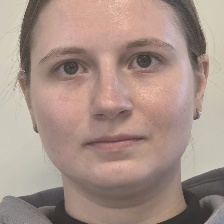

Rekonstruētā sejas forma ar detaļām


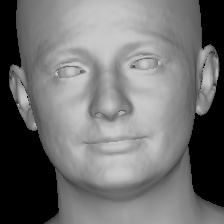

In [20]:
from pathlib import Path
from PIL import Image
from IPython.display import display

# Norāda pārbaudāmos attēlus un to paskaidrojumus
atteli = {
    "DECA apgrieztā ievade":
        "frontal/frontal_inputs.jpg",
    "Rekonstruētā sejas forma ar detaļām":
        "frontal/frontal_shape_detail_images.jpg"
}

# Parāda rezultātus tikai šīs Colab piezīmju grāmatas izvadē
for paskaidrojums, relativais_cels in atteli.items():
    fails = Path("/content/DECA/results/frontal") / relativais_cels
    print(paskaidrojums)
    with Image.open(fails) as attels:
        display(attels.copy())

In [16]:
from pathlib import Path
from io import BytesIO
from PIL import Image, ImageOps
from google.colab import files

# Norāda atsevišķas vietas profila oriģinālam un darba kopijai
originals = Path("/content/DECA/inputs/originals/profile/profile.jpg")
kopija = Path("/content/DECA/inputs/processed/profile/profile.jpg")
assert not originals.exists() and not kopija.exists(), "Profila fails jau eksistē."

# Atver viena profila JPG attēla izvēli
augšuplade = files.upload()
assert len(augšuplade) == 1, "Jāizvēlas tikai profila attēls."
saturs = next(iter(augšuplade.values()))

# Pārbauda formātu un sagatavo pareizi orientētu darba attēlu
with Image.open(BytesIO(saturs)) as attels:
    assert attels.format == "JPEG", "Nepieciešams JPEG attēls."
    darba_attels = ImageOps.exif_transpose(attels).convert("RGB")

# Saglabā oriģinālu nemainītu un samazina tikai darba kopiju
originals.parent.mkdir(parents=True, exist_ok=True)
kopija.parent.mkdir(parents=True, exist_ok=True)
originals.write_bytes(saturs)
darba_attels.thumbnail((1600, 1600), Image.Resampling.LANCZOS)
darba_attels.save(kopija, quality=95)

print("Oriģināls:", originals)
print("Darba kopija:", kopija)
print("Darba kopijas izmērs:", darba_attels.size)

Saving profile.jpg to profile.jpg
Oriģināls: /content/DECA/inputs/originals/profile/profile.jpg
Darba kopija: /content/DECA/inputs/processed/profile/profile.jpg
Darba kopijas izmērs: (1200, 1600)


In [17]:
import os
import subprocess
from pathlib import Path

# Sagatavo vidi jau kompilētā renderētāja izmantošanai
vide = os.environ.copy()
vide["PATH"] = "/content/deca-env/bin:" + vide["PATH"]
vide["MAX_JOBS"] = "2"
vide["TORCH_CUDA_ARCH_LIST"] = "7.5"

# Izveido atsevišķu profila rezultātu mapi
izvade = Path("/content/DECA/results/profile")
izvade.mkdir(parents=True, exist_ok=True)

# Palaiž profila rekonstrukciju ar pretskatam izmantotajiem iestatījumiem
komanda = [
    "/content/deca-env/bin/python", "demos/demo_reconstruct.py",
    "-i", "/content/DECA/inputs/processed/profile/profile.jpg",
    "-s", str(izvade),
    "--device", "cuda",
    "--iscrop", "True",
    "--rasterizer_type", "standard",
    "--useTex", "False",
    "--render_orig", "False",
    "--saveObj", "True",
    "--saveVis", "True",
    "--saveImages", "True"
]

# Saglabā konsoles izvadi, arī tad, ja rekonstrukcija neizdodas
zurnals = izvade / "reconstruction.log"
print("Notiek profila rekonstrukcija…", flush=True)

with zurnals.open("w") as fails:
    rezultats = subprocess.run(
        komanda, cwd="/content/DECA", env=vide,
        stdout=fails, stderr=subprocess.STDOUT, text=True
    )

# Parāda izpildes rezultātu un saglabātos failus
print("\n".join(zurnals.read_text().splitlines()[-60:]))
print("Atgriešanās kods:", rezultats.returncode)
for fails in sorted(izvade.rglob("*")):
    if fails.is_file():
        print(fails.relative_to(izvade))

Notiek profila rekonstrukcija…
/content/deca-env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/content/deca-env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/content/DECA/decalib/deca.py:89: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be 

Apgrieztā profila ievade


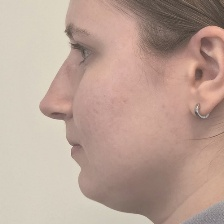

No profila iegūtā sejas ģeometrija


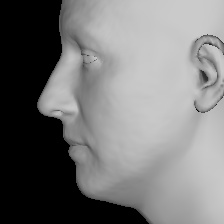

In [21]:
from pathlib import Path
from PIL import Image
from IPython.display import display

# Norāda profila ievadi un rekonstruētās ģeometrijas attēlu
mape = Path("/content/DECA/results/profile/profile")
atteli = {
    "Apgrieztā profila ievade": "profile_inputs.jpg",
    "No profila iegūtā sejas ģeometrija": "profile_shape_detail_images.jpg"
}

# Parāda abus attēlus Colab piezīmju grāmatā
for nosaukums, fails in atteli.items():
    print(nosaukums)
    with Image.open(mape / fails) as attels:
        display(attels.copy())

## 4. Vizualizēt un analizēt rezultātus

In [22]:
from pathlib import Path
import plotly.graph_objects as go

for ievade in ["frontal", "profile"]:
    # Nolasa saglabātā modeļa virsotnes un trijstūrus
    fails = Path(f"/content/DECA/results/{ievade}/{ievade}/{ievade}_detail.obj")
    virsotnes, skaldnes = [], []

    with fails.open() as saturs:
        for rinda in saturs:
            dalas = rinda.split()
            if dalas and dalas[0] == "v":
                virsotnes.append([float(v) for v in dalas[1:4]])
            elif dalas and dalas[0] == "f":
                skaldnes.append([int(v.split("/")[0]) - 1 for v in dalas[1:4]])

    # Izveido 3D skatu no modeļa sākotnējās ģeometrijas
    x, y, z = zip(*virsotnes)
    i, j, k = zip(*skaldnes)
    skats = go.Figure(go.Mesh3d(
        x=x, y=y, z=z, i=i, j=j, k=k,
        color="lightgray", flatshading=False
    ))

    # Paslēpj koordinātu asis un norāda ievades attēlu
    skats.update_layout(
        title=f"DECA — ievade: {ievade}.jpg",
        height=600, margin=dict(l=0, r=0, t=50, b=0),
        scene=dict(
            xaxis=dict(visible=False),
            yaxis=dict(visible=False),
            zaxis=dict(visible=False),
            aspectmode="data",
            camera=dict(eye=dict(x=0, y=0, z=2.5), up=dict(x=0, y=1, z=0))
        )
    )

    # Parāda grozāmu modeli un iespēju saglabāt PNG attēlu
    skats.show(renderer="colab", config={
        "displaylogo": False,
        "toImageButtonOptions": {
            "format": "png", "filename": f"{ievade}_skats",
            "width": 1000, "height": 800, "scale": 1
        }
    })

Abu ievades attēlu detalizētie OBJ modeļi tika attēloti interaktīvā Plotly skatītājā. Katram modelim tika saglabāti četri skatpunkti - pretskats, profili abos virzienos un trīs ceturtdaļu skats vienā virzienā, kopā iegūstot astoņus attēlus. Modeļu pagriešana maina tikai virtuālās kameras skatpunktu, nevis rekonstruēto ģeometriju, un nerada jaunus sejas mērījumus.

Abās rekonstrukcijās vizuāli šķiet saglabāts sejas platums, deguna kopējā forma, žokļa līnija un zods, redzamas arī krokas pie deguna un vaigiem. Būtiskas deformācijas netika novērotas, tomēr deguna formai ir nelielas atšķirības, kā arī no pretskata iegūtajā modelī acu lielums šķiet labāk saglabāts nekā no profila iegūtajā modelī. Pelēkajā skatītājā redzamais ēnojums ir atkarīgs arī no renderētāja apgaismojuma, tāpēc to nevar uzskatīt par pierādījumu oriģinālās attēla tekstūras saglabāšanai.

Salīdzinot abus modeļus vienādā trīs ceturtdaļu skatā, pretskata rekonstrukcija subjektīvi šķiet līdzīgāka oriģinālajai sejai, jo tajā ir labāk izteiktas ieloces un iedobes vaigu un deguna apvidū, tacu profila rekonstrukcijā šīs detaļas ir mazāk izteiktas, un atšķiras rekonstruētā sejas izteiksme. Atšķirības var būt saistītas ar galvas pozu, redzamās informācijas apjomu un izteiksmes vai apgaismojuma atšķirībām starp ievadēm.

No viena fotoattēla nav iespējams tieši novērot visu sejas virsmu, jo pretskatā ir ierobežota informācija par sejas dziļumu, savukārt profilā nav redzama pretējā sejas puse, un šo apgabalu ģeometrija ir atkarīga no DECA apmācībā apgūtajām sakarībām un FLAME formas modeļa, tādēļ vizuālā līdzība un vienmērīga modeļa pagriešana neapliecina pareizus fiziskos izmērus. Ģeometriskā precizitāte milimetros šajā darbā netika noteikta.

Neatkarīgai vizuālai pārbaudei varētu uzņemt papildu fotoattēlu aptuveni 45° leņķī ar neitrālu izteiksmi un līdzīgu apgaismojumu. Neizmantojot šo attēlu rekonstrukcijai, varētu salīdzināt deguna, lūpu un zoda kontūras ar katra modeļa atbilstošo skatpunktu. Šāda pārbaude palīdzētu atklāt formas neatbilstības, taču nenodrošinātu metriskas precizitātes mērījumu.

### Izmantotie avoti un MI palīdzība

Darbā tika izmantota DECA projekta oficiālā realizācija un tās demonstrācijas skripts. Vides sagatavošanai un vizualizācijai tika izmantota attiecīgo bibliotēku dokumentācija:

- DECA projekts (https://github.com/yfeng95/DECA)
- FLAME modelis (https://flame.is.tue.mpg.de/)
- PyTorch iepriekšējo versiju instalēšana (https://pytorch.org/get-started/previous-versions/)
- uv vides izveidošana (https://docs.astral.sh/uv/pip/environments/)
- face-alignment projekts (https://github.com/1adrianb/face-alignment)
- Kornia projekts (https://github.com/kornia/kornia)
- gdown lejupielādes rīks (https://github.com/wkentaro/gdown)
- Plotly 3D režģu vizualizācija (https://plotly.com/python/3d-mesh/)

Koda izstrādē, vides konfigurēšanā un saderības kļūdu novēršanā kā palīgrīks tika izmantots MI rīks ChatGPT.

In [23]:
from pathlib import Path
import subprocess

projekts = Path("/content/DECA")
fails = projekts / ".gitignore"

# Nosaka nepublicējamos modeļus, personīgos datus un pagaidu failus
noteikumi = """
# Izslēdz ārējos modeļus un lejupielādētos arhīvus.
*.pkl
*.tar
*.zip
*.pt
*.pth
*.ckpt
/data/FLAME2020/

# Izslēdz personīgos attēlus, modeļus un izpildes rezultātus.
/inputs/
/results/
/frontal*.jpg
/profile*.jpg

# Izslēdz rezerves kopijas un piezīmju grāmatas pagaidu failus.
*.original
.ipynb_checkpoints/
"""

# Papildina esošo gitignore, saglabājot sākotnējos noteikumus
atzime = "# Praktiskā darba nepublicējamie faili"
esosais = fails.read_text() if fails.exists() else ""
if atzime not in esosais:
    fails.write_text(esosais + "\n" + atzime + "\n" + noteikumi)

# Pārbauda, vai būtiskos ceļus izslēdz gitignore noteikumi
parbaude = subprocess.run(
    [
        "git", "check-ignore", "-v",
        "data/generic_model.pkl",
        "data/deca_model.tar",
        "inputs/originals/frontal/frontal.jpg",
        "inputs/originals/profile/profile.jpg",
        "results/frontal/frontal/frontal_detail.obj"
    ],
    cwd=projekts, capture_output=True, text=True
)
print("Ignorēšanas noteikumu pārbaude:")
print(parbaude.stdout)
print(parbaude.stderr)

# Pārbauda, vai aizsargājamie faili jau ir Git uzskaitē
uzskaite = subprocess.run(
    [
        "git", "ls-files", "--",
        "*.pkl", "*.tar", "*.zip", "*.pt", "*.pth", "*.ckpt",
        "inputs/**", "results/**", "*.original",
        "frontal*.jpg", "profile*.jpg"
    ],
    cwd=projekts, capture_output=True, text=True, check=True
)
print("Aizsargājamie faili, kas jau ir Git uzskaitē:")
print(uzskaite.stdout or "Nav atrasti.")

Ignorēšanas noteikumu pārbaude:
.gitignore:53:*.pkl	data/generic_model.pkl
.gitignore:54:*.tar	data/deca_model.tar
.gitignore:62:/inputs/	inputs/originals/frontal/frontal.jpg
.gitignore:62:/inputs/	inputs/originals/profile/profile.jpg
.gitignore:63:/results/	results/frontal/frontal/frontal_detail.obj


Aizsargājamie faili, kas jau ir Git uzskaitē:
Nav atrasti.
